## Read embeddings

In [2]:
import pandas as pd
import pandas as pd
# MODELS PARAMS
## PARAMETERS
RUNS = 10
total_splits = 1

MODELS_DESCRIPTIONS = {
    "single_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10],
    },
    "single_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_single_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 1,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10]
    },
    "multiple_allele_balanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_balanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10]
    },
    "multiple_allele_imbalanced": {
        "path": "experiment_results/alleles_with_groups_multiple_allele_imbalanced_data/",
        "states": 25,
        "params_string": "5-min_iters",
        "combination_size": 2,
        "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
        "target_lengths": [9, 10]
    },
    "mix_of_alleles":
        {
            "path": "experiment_results/alleles_with_groups/",
            "states": 25,
            "params_string": "5-min_iters",
            "alleles": ['HLA-A*01:01', 'HLA-A*03:01'],
            "target_lengths": [9, 10],
            "combination_size":2
        },
    # "mix_of_alleles_balanced":
    # {
    #     "alleles": ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'],
    #     "path": "experiment_results/alleles_with_groups_balanced/",
    #     "states": 25,
    #     "params_string": "5-min_iters",
    #     "target_lengths": [9, 10]
    # }
}

# selected_model = MODELS_DESCRIPTIONS["multiple_allele_imbalanced"]
# selected_model = MODELS_DESCRIPTIONS["multiple_allele_balanced"]
# selected_model = MODELS_DESCRIPTIONS["single_allele_imbalanced"]
selected_model = MODELS_DESCRIPTIONS["single_allele_balanced"]


In [3]:
#Selected combination
# combination = ('HLA-A*01:01', 'HLA-A*02:01')
# combination = ('HLA-A*01:01', 'HLA-A*03:01')

# combination = ('HLA-A*02:01', 'HLA-A*03:01')
# combination = ('HLA-A*01:01','HLA-A*02:01', 'HLA-A*03:01')

# combination = ('HLA-A*01:01',)
combination = ('HLA-A*03:01',)
# combination = ('HLA-A*02:01',)

In [4]:
combination

('HLA-A*03:01',)

In [5]:
for allele_name in combination:
    assert allele_name in selected_model['alleles'], f"{allele_name} not in "
selected_alleles = list(combination)


states = selected_model['states']
TARGET_LENGTHS = selected_model['target_lengths']
selected_combination = "+".join(selected_alleles).replace('-', '_').replace('*', '_').replace(':', '_')
selected_model_split = 0 # should match to data split (if original train/test used) in order to have true test case
selected_model_run = "combined"
target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])

In [6]:
mixed_model_bw =f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'
mixed_model_bwv = f'{selected_model_run}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{selected_combination}-{selected_model_split}_plus_viterbi'
mixed_model_v = f'{selected_model_run}_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{selected_combination}-{selected_model_split}'

name_to_model_root = dict()
name_to_model_root[mixed_model_bw] = selected_model['path']
name_to_model_root[mixed_model_bwv] = selected_model['path']
name_to_model_root[mixed_model_v] = selected_model['path']

In [7]:
def load_embeddings(model):
    print(f"model {model}")
    TARGET_PATH_TO_FILES = name_to_model_root[model] + model
    # Train 
    train_df =  pd.read_csv("{}/train_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)
    # Test 
    test_df =  pd.read_csv("{}/test_embedding.csv".format(TARGET_PATH_TO_FILES),sep=";",index_col=0)

    # paths_df['path'] = paths_df['path'].apply(pd.eval)
    # paths_df['path'] = paths_df['path'].astype(list)
    return  train_df, test_df


In [8]:
%%time
per_model_type_train_embeddings = dict()
per_model_type_test_embeddings = dict()
# BW
train_df, test_df = load_embeddings(mixed_model_bw)
per_model_type_train_embeddings['bw'] = train_df
per_model_type_test_embeddings['bw'] = test_df
# BWV
train_df, test_df = load_embeddings(mixed_model_bwv)
per_model_type_train_embeddings['bwv'] = train_df
per_model_type_test_embeddings['bwv'] = test_df
# V
train_df, test_df = load_embeddings(mixed_model_v)
per_model_type_train_embeddings['v'] = train_df
per_model_type_test_embeddings['v'] = test_df

model combined_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_03_01-0
model combined_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_03_01-0_plus_viterbi
model combined_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_03_01-0
Wall time: 1min 13s


# Scanpy

In [9]:
target_df = per_model_type_train_embeddings['v']

In [10]:
target_df.index = target_df['peptide'].values

In [11]:
dropped_columns = target_df.drop(columns=['allele', 'peptide']).copy()
transposed = dropped_columns.T.copy()

In [12]:
target_df['allele'].value_counts()

HLA-A*03:01        6577
HLA-A*03:01_imm      69
Name: allele, dtype: int64

In [13]:
import scanpy as sc
import anndata as ad
import numpy as np

In [14]:
obs = pd.DataFrame({"peptide": target_df.index.values, "allele": target_df['allele'].values, "length": target_df.index.str.len().values})
var = pd.DataFrame({"path":target_df.columns.drop(['allele', 'peptide'])})
X = np.exp(target_df.drop(columns=['allele', 'peptide']).values)

In [15]:
adata = ad.AnnData(X, obs=obs, var=var, dtype='float')

D:\Tools\Python\Anaconda\envs\pomegranate\lib\site-packages\anndata\_core\anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [16]:
adata

AnnData object with n_obs × n_vars = 6646 × 5000
    obs: 'peptide', 'allele', 'length'
    var: 'path'

In [17]:
adata.obs

,peptide,allele,length
0,STNSFALNK,HLA-A*03:01,9
1,GISNPITTSK,HLA-A*03:01,10
2,ISYDPKFEK,HLA-A*03:01,9
3,KILNLRFLGK,HLA-A*03:01,10
4,VVWEPAWAAK,HLA-A*03:01,10
...,...,...,...
6641,MQYLNPPPY,HLA-A*03:01,9
6642,TTVPHVFSK,HLA-A*03:01,9
6643,LSLGVAALYK,HLA-A*03:01,10
6644,DTIESAKTK,HLA-A*03:01,9


In [18]:
adata.var

,path
0,0
1,1
2,2
3,3
4,4
...,...
4995,4995
4996,4996
4997,4997
4998,4998


In [19]:
adata.X

array([[0.56904285, 0.57343404, 0.59863314, ..., 0.62854751, 0.49454808,
        0.43992979],
       [0.44787245, 0.45132859, 0.49014111, ..., 0.47731991, 0.3990384 ,
        0.56668162],
       [0.47026854, 0.4328928 , 0.48505018, ..., 0.50810196, 0.45348145,
        0.52380675],
       ...,
       [0.46486617, 0.46845345, 0.39660162, ..., 0.38461324, 0.33730642,
        0.46682054],
       [0.42711836, 0.47120899, 0.46936561, ..., 0.51841653, 0.48544888,
        0.50142954],
       [0.5166479 , 0.52063478, 0.51673891, ..., 0.46068315, 0.42678065,
        0.44267698]])

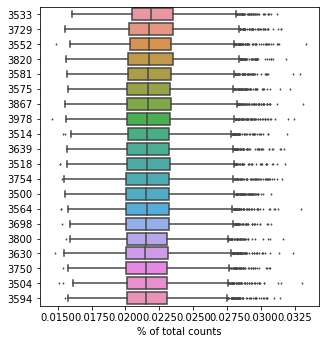

In [20]:
sc.pl.highest_expr_genes(adata, n_top=20, )

## 1. Normalize

In [28]:
# sc.pp.scale(adata)

In [29]:
adata.X

array([[0.56904285, 0.57343404, 0.59863314, ..., 0.62854751, 0.49454808,
        0.43992979],
       [0.44787245, 0.45132859, 0.49014111, ..., 0.47731991, 0.3990384 ,
        0.56668162],
       [0.47026854, 0.4328928 , 0.48505018, ..., 0.50810196, 0.45348145,
        0.52380675],
       ...,
       [0.46486617, 0.46845345, 0.39660162, ..., 0.38461324, 0.33730642,
        0.46682054],
       [0.42711836, 0.47120899, 0.46936561, ..., 0.51841653, 0.48544888,
        0.50142954],
       [0.5166479 , 0.52063478, 0.51673891, ..., 0.46068315, 0.42678065,
        0.44267698]])

In [30]:
sc.pp.normalize_total(adata) # Total-count normalize (library-size correct) the data matrix X to 10,000 reads per cell, so that counts become comparable among cells.
sc.pp.log1p(adata) # log-normalization

In [21]:
adata.X

array([[0.56904285, 0.57343404, 0.59863314, ..., 0.62854751, 0.49454808,
        0.43992979],
       [0.44787245, 0.45132859, 0.49014111, ..., 0.47731991, 0.3990384 ,
        0.56668162],
       [0.47026854, 0.4328928 , 0.48505018, ..., 0.50810196, 0.45348145,
        0.52380675],
       ...,
       [0.46486617, 0.46845345, 0.39660162, ..., 0.38461324, 0.33730642,
        0.46682054],
       [0.42711836, 0.47120899, 0.46936561, ..., 0.51841653, 0.48544888,
        0.50142954],
       [0.5166479 , 0.52063478, 0.51673891, ..., 0.46068315, 0.42678065,
        0.44267698]])

## 2. Highly variable features

In [22]:
import matplotlib.pyplot as plt
# sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)
# sc.pl.highly_variable_genes(adata, show=False) # can not scale only x

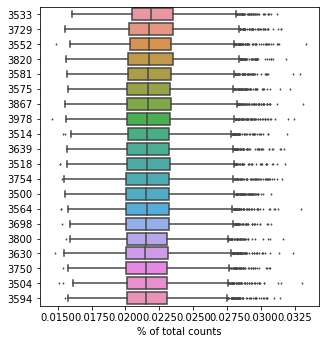

In [23]:
sc.pl.highest_expr_genes(adata, n_top=20, )

## 3. PCA

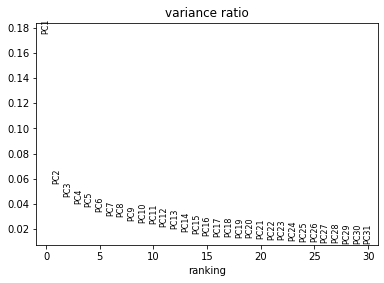

In [24]:
sc.tl.pca(adata, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata)

## 4. Neighborhood graph and umap

In [25]:
from itertools import product
import seaborn as sns
import matplotlib.pyplot as plt

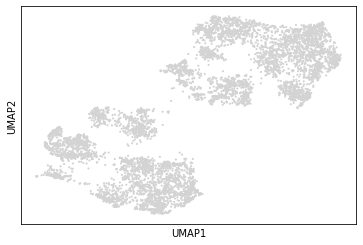

In [27]:
sc.pp.neighbors(adata, n_neighbors=25, n_pcs=15, metric="euclidean")
sc.tl.umap(adata, min_dist=0.01)
sc.pl.umap(adata)

## 5.  Cell clusters

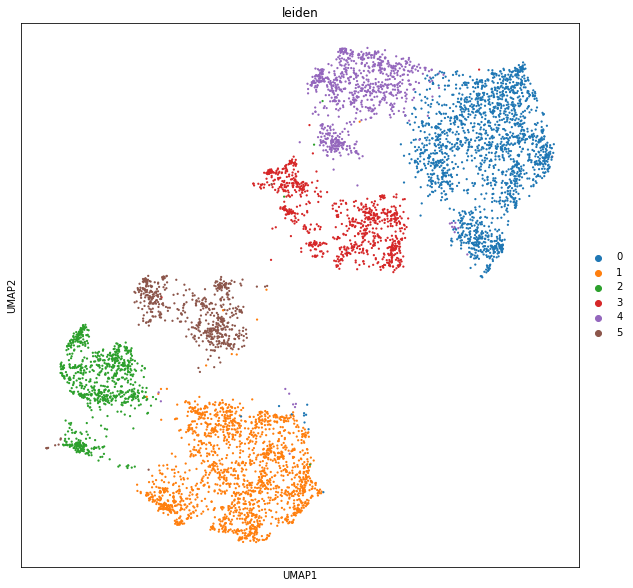

In [28]:
from matplotlib.pyplot import rc_context
with rc_context({'figure.figsize': (10, 10)}):
    sc.tl.leiden(adata, resolution=0.45)
    sc.tl.louvain(adata, resolution=0.3)
    sc.pl.umap(adata, color='leiden', s=20)
    # sc.pl.umap(adata, color='louvain', s=20)

<AxesSubplot:xlabel='0', ylabel='1'>

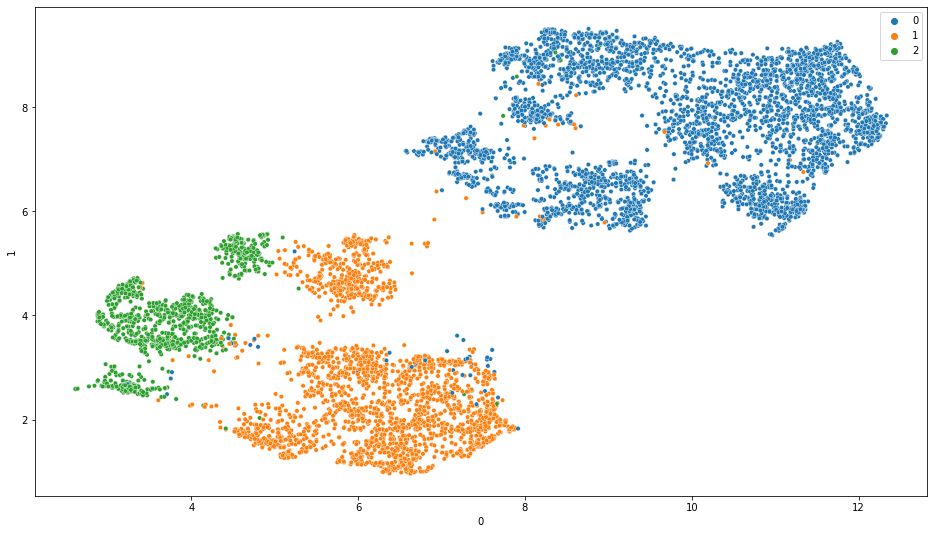

In [29]:
plt.figure(figsize=(16,9))
df = pd.DataFrame(adata.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=20, hue=adata.obs['louvain'].values)

## 6. Color by allele

In [30]:
adata_copy = adata_copy = adata[~adata.obs['allele'].str.contains('imm')]

D:\Tools\Python\Anaconda\envs\pomegranate\lib\site-packages\anndata\compat\_overloaded_dict.py:106: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  self.data[key] = value
D:\Tools\Python\Anaconda\envs\pomegranate\lib\contextlib.py:126: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  next(self.gen)


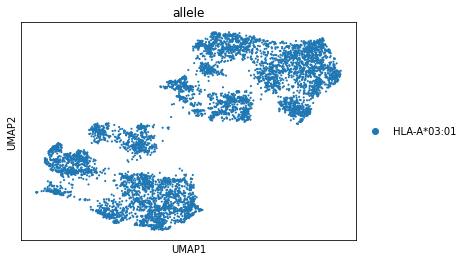

In [31]:
sc.pl.umap(adata_copy, color="allele")

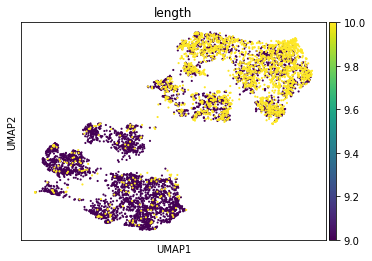

In [32]:
sc.pl.umap(adata_copy, color="length")

<AxesSubplot:xlabel='0', ylabel='1'>

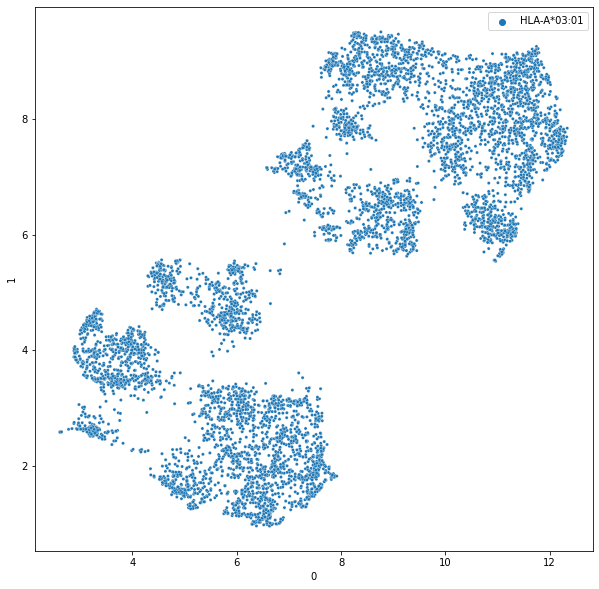

In [33]:
plt.figure(figsize=(10,10))
df = pd.DataFrame(adata_copy.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=10, hue=adata_copy.obs['allele'].values)

<AxesSubplot:xlabel='0', ylabel='1'>

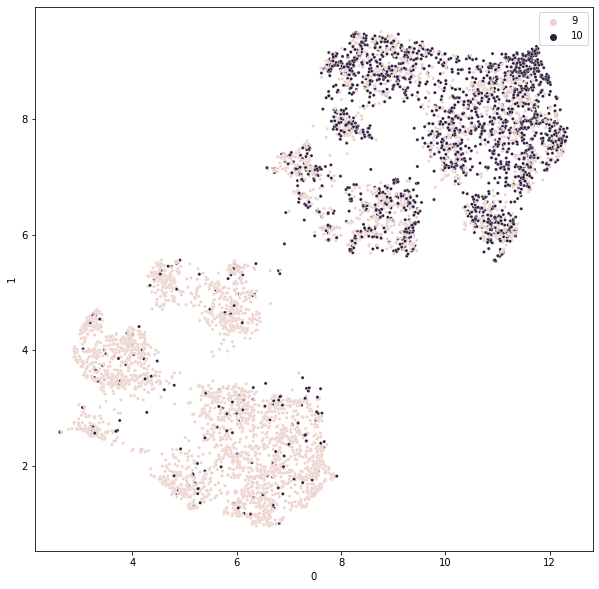

In [34]:
plt.figure(figsize=(10,10))
df = pd.DataFrame(adata_copy.obsm['X_umap'])
sns.scatterplot(data=df, x=0, y=1,s=10, hue=adata_copy.obs['length'].values)

## Color by immunogenicity

In [35]:
adata.obs['immunogenic'] = adata.obs['allele'].str.contains('imm').astype(int)
adata.obs

,peptide,allele,length,leiden,louvain,immunogenic
0,STNSFALNK,HLA-A*03:01,9,5,1,0
1,GISNPITTSK,HLA-A*03:01,10,0,0,0
2,ISYDPKFEK,HLA-A*03:01,9,1,1,0
3,KILNLRFLGK,HLA-A*03:01,10,0,0,0
4,VVWEPAWAAK,HLA-A*03:01,10,0,0,0
...,...,...,...,...,...,...
6641,MQYLNPPPY,HLA-A*03:01,9,0,0,0
6642,TTVPHVFSK,HLA-A*03:01,9,1,1,0
6643,LSLGVAALYK,HLA-A*03:01,10,4,0,0
6644,DTIESAKTK,HLA-A*03:01,9,1,1,0


<AxesSubplot:xlabel='0', ylabel='1'>

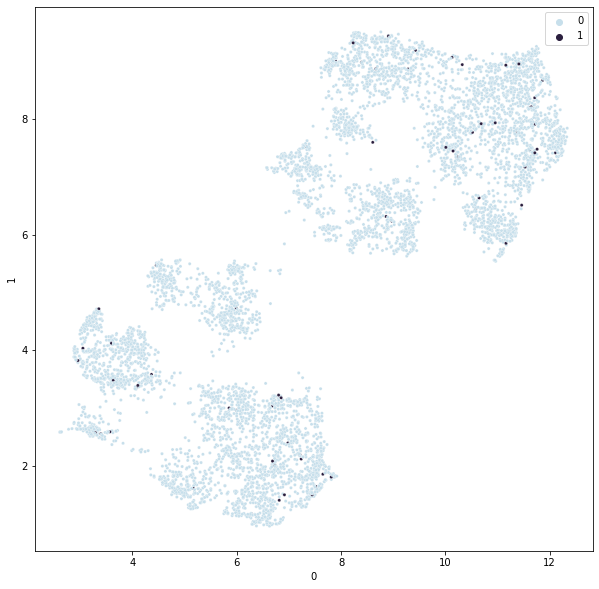

In [36]:
plt.figure(figsize=(10,10))
df = pd.DataFrame(adata.obsm['X_umap'])
colors = sns.color_palette("ch:s=.25,rot=-.25", 2)
sns.scatterplot(data=df, x=0, y=1,s=10, hue=adata.obs['immunogenic'].values, palette=colors)

## 7. Plot cluster motifs

In [37]:
peptides_df = adata.obs.copy()

In [38]:
import logomaker
def make_logo(df, length=9, cluster_num=0, ax=None):
    filtered = df[df['length'] == length]
    if len(filtered) > 0:
        matrix = logomaker.alignment_to_matrix(filtered['peptide'].values)
        info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
        counts = dict(filtered['allele'].value_counts())
        counts = dict(sorted(counts.items()))
        # prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
        ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', ax=ax)
        ww_logo.ax.set_title(f"Cluster {cluster_num} Allele counts:\n {counts}")

In [39]:
def plot_all_cluster_motifs(source_df, cluster_column = 'leiden', target_length=9 ):
    unique_clusters = peptides_df[cluster_column].unique()
    fig, axes = plt.subplots(nrows=len(unique_clusters), ncols=2, figsize=(16,3*len(unique_clusters)))
    for i, cluster_num in enumerate(unique_clusters):
        print(i)
        ax = axes[i, 0]
        df = source_df[source_df[cluster_column] == cluster_num]
        make_logo(df,length=target_length, cluster_num=cluster_num, ax=ax)
        # Additionaly plot immunogenic peptides
        ax = axes[i, 1]
        df = source_df[(source_df[cluster_column] == cluster_num) & (source_df['immunogenic'] == 1)]
        print(len(df))
        if len(df) > 0:
            make_logo(df,length=target_length, cluster_num=cluster_num, ax=ax)
    plt.tight_layout()



0
2
1
24
2
19
3
9
4
12
5
3


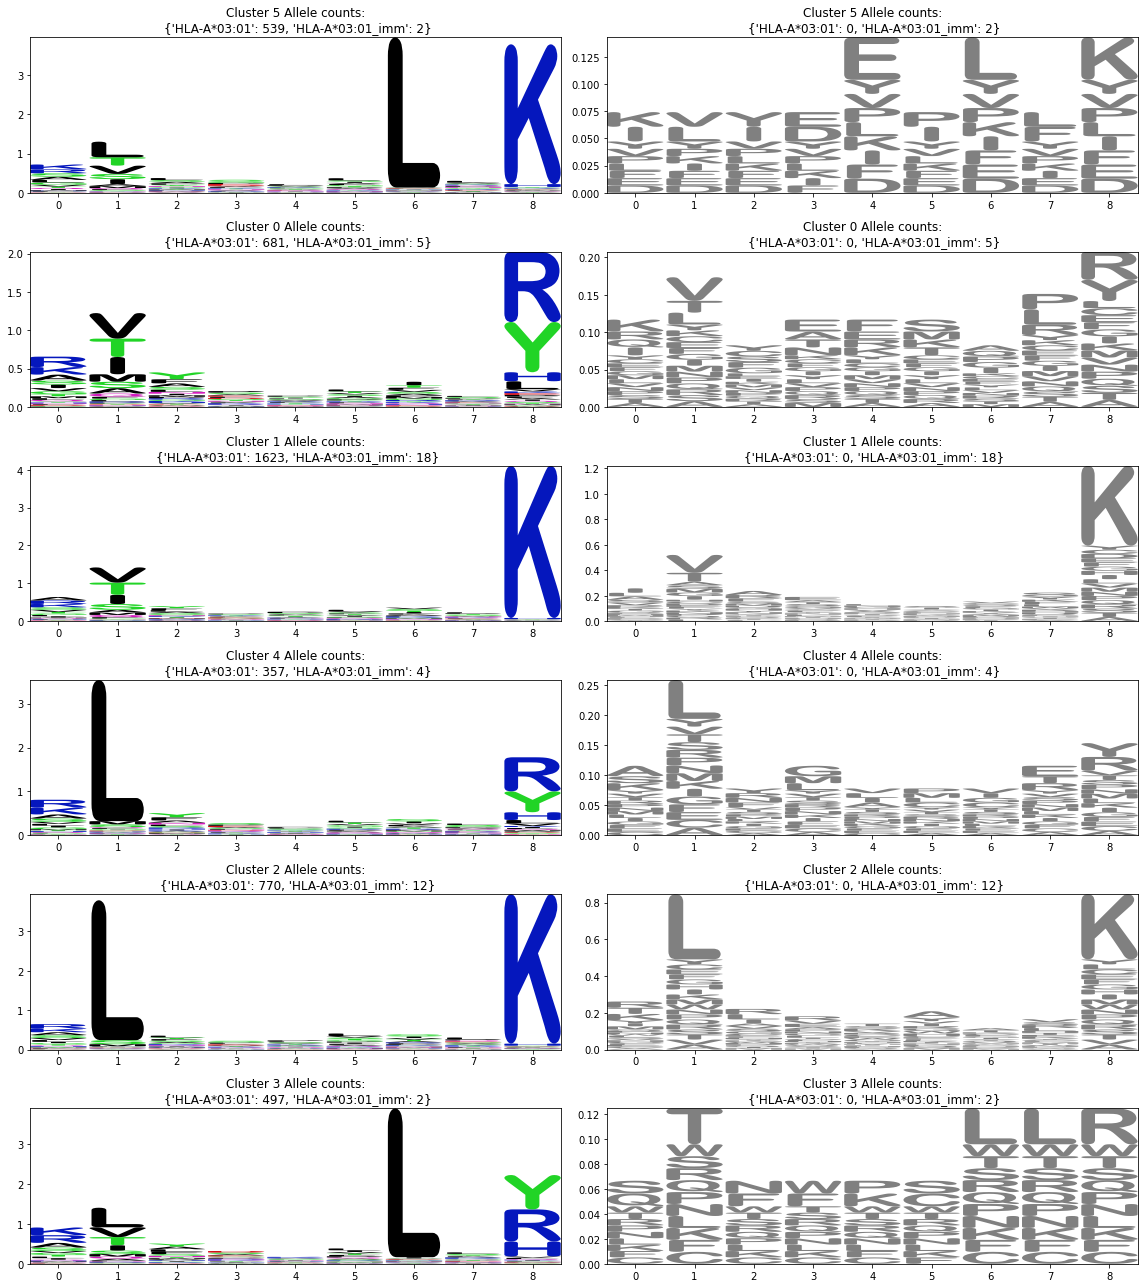

In [40]:
plot_all_cluster_motifs(peptides_df, 'leiden',9)

0
2
1
24
2
19
3
9
4
12
5
3


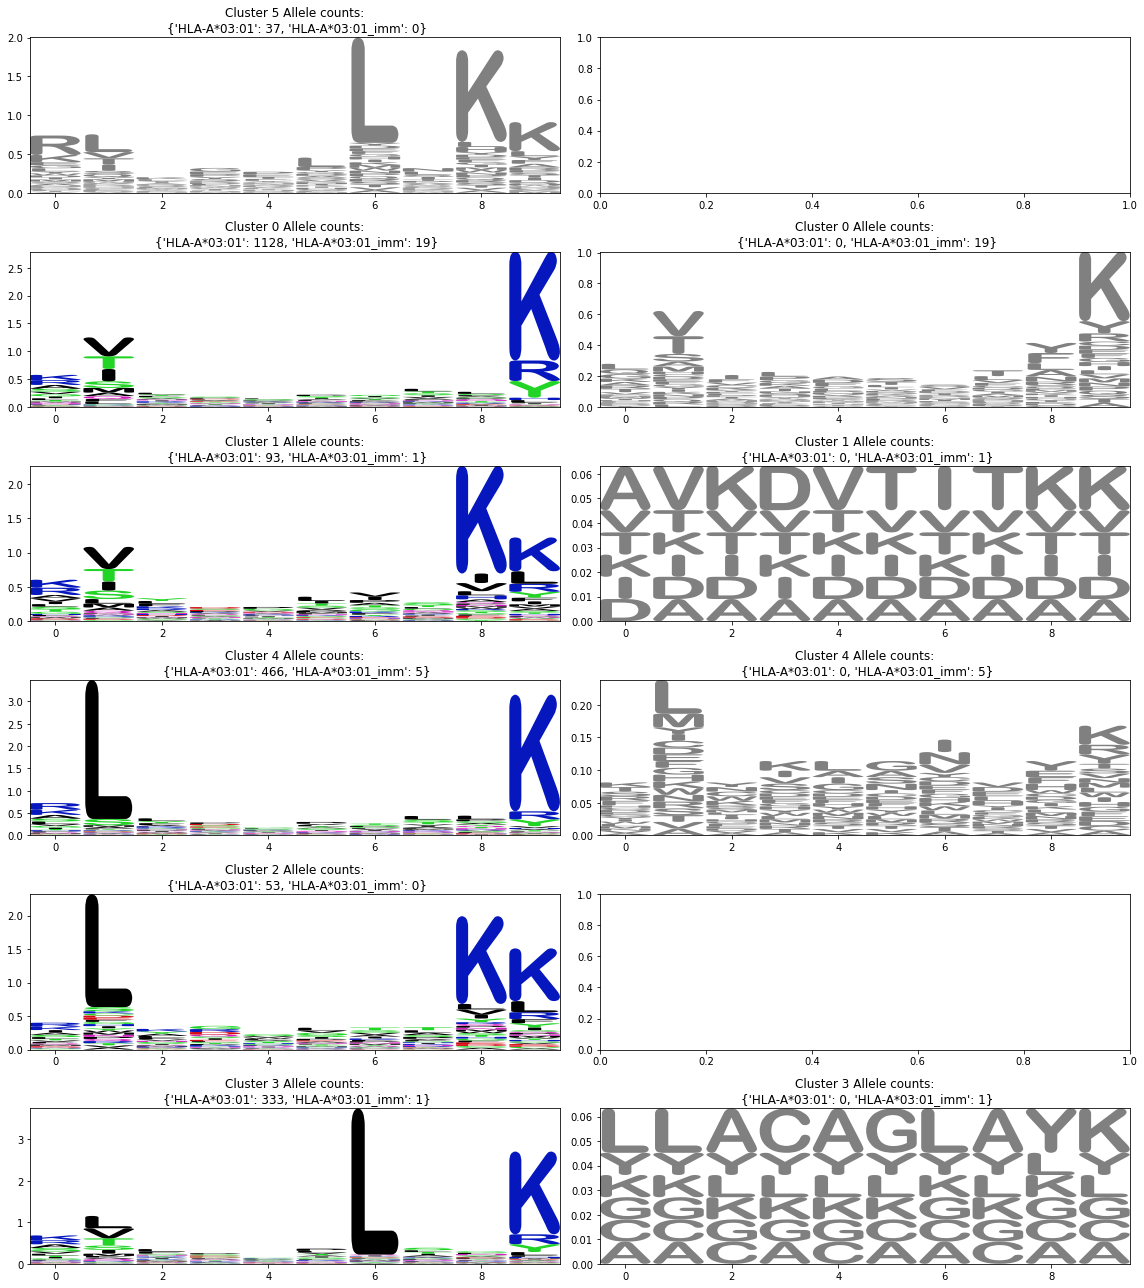

In [41]:
plot_all_cluster_motifs(peptides_df, 'leiden', 10)

kk cluster 2

In [43]:
analysis_df = peptides_df[(peptides_df['leiden'] == '2') & (peptides_df['length'] == 10)]

In [44]:
len(analysis_df)

53

In [45]:
analysis_df.head(30)

,peptide,allele,length,leiden,louvain,immunogenic
16,LLYQGVYLKK,HLA-A*03:01,10,2,2,0
141,SLIGYLITKK,HLA-A*03:01,10,2,2,0
378,ILARWSSFKK,HLA-A*03:01,10,2,2,0
628,FLAQALSPKL,HLA-A*03:01,10,2,2,0
909,RLVQGSILKK,HLA-A*03:01,10,2,2,0
1028,ILKRWGQLKK,HLA-A*03:01,10,2,2,0
1055,TLYISECLKK,HLA-A*03:01,10,2,2,0
1184,KLFDFVNAKK,HLA-A*03:01,10,2,2,0
1234,QLCYCPASKK,HLA-A*03:01,10,2,2,0
1235,FLILCFTIKR,HLA-A*03:01,10,2,1,0


In [46]:
analysis_df['peptide'].str.contains('KK$').value_counts()

True     31
False    22
Name: peptide, dtype: int64

In [47]:
analysis_df['peptide'].str.contains('K[^K]$').value_counts()

False    37
True     16
Name: peptide, dtype: int64

In [48]:
analysis_df['peptide'].str.contains('[^K]K$').value_counts()

False    47
True      6
Name: peptide, dtype: int64

kkcluster 1

In [49]:
analysis_df = peptides_df[(peptides_df['leiden'] == '1') & (peptides_df['length'] == 10)]

In [50]:
len(analysis_df)

94

In [51]:
analysis_df['peptide'].str.contains('KK$').value_counts()

False    54
True     40
Name: peptide, dtype: int64

In [52]:
analysis_df['peptide'].str.contains('K[^K]$').value_counts()

False    56
True     38
Name: peptide, dtype: int64

In [53]:
analysis_df['peptide'].str.contains('[^K]K$').value_counts()

False    89
True      5
Name: peptide, dtype: int64

In [62]:
analysis_df.iloc[75:100][['peptide', 'length']]

,peptide,length
5393,KLLDEAIQAV,10
5482,LALEVARQKR,10
5489,RVKLPSGSKK,10
5700,KTIDASVSKK,10
5773,VVLGNIIKKK,10
5922,FVFPLNSKVK,10
5948,KSFPGIPLHH,10
5969,SLRTACVPHR,10
6081,ISWEALRWKA,10
6163,AQYQFTGIKK,10


In [63]:
test_df = analysis_df[~((analysis_df['peptide'].str.contains('[^K]K$')) | 
                         (analysis_df['peptide'].str.contains('K[^K]$')) |
                          (analysis_df['peptide'].str.contains('KK$')))
                         ]

In [64]:
test_df               

,peptide,allele,length,leiden,louvain,immunogenic
167,KLFPGSPAIY,HLA-A*03:01,10,1,1,0
1744,KIDKLTFQIY,HLA-A*03:01,10,1,1,0
2544,KTKDPTAALR,HLA-A*03:01,10,1,0,0
3240,GLLDSIKMIY,HLA-A*03:01,10,1,1,0
3951,LTDFGLSKIM,HLA-A*03:01,10,1,1,0
4159,KLSYGIATVR,HLA-A*03:01,10,1,1,0
4661,ILDDNLYKVY,HLA-A*03:01,10,1,1,0
4945,VTLAILTALR,HLA-A*03:01,10,1,1,0
5393,KLLDEAIQAV,HLA-A*03:01,10,1,1,0
5948,KSFPGIPLHH,HLA-A*03:01,10,1,1,0


In [95]:
target_df.loc['RLNDRYPKKL'].drop(labels=['allele', 'peptide']).astype(float).sort_values(ascending=False).head(20)

98     -0.318822
101    -0.342753
354    -0.368054
2927   -0.383446
2648   -0.384295
0      -0.384449
393    -0.389404
27     -0.394635
151    -0.401635
218    -0.409427
742    -0.410926
390    -0.411313
2858   -0.415922
2667   -0.417967
164    -0.418814
160    -0.421213
3988   -0.429674
135    -0.432491
317    -0.433329
3099   -0.433387
Name: RLNDRYPKKL, dtype: float64

In [66]:
target_df.loc['FLAQALSPKL'][98]

-0.5738168380742605

In [67]:
#0-th model
filename = 'D:\\Projects\\MHC_predictor\\experiments\\length_dependent_hmm\\experiment_results\\alleles_with_groups_single_allele_balanced_data\\0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_03_01-0\\viterbi_paths_df.csv'


In [68]:
df = pd.read_csv(filename, sep=';')

In [124]:
top500 = target_df.loc['RLNDRYPKKL'].drop(labels=['allele', 'peptide']).astype(float).sort_values(ascending=False).head(500).index

In [125]:
top500 = top500[top500.astype(int) < 500].astype(int)

In [126]:
top500

Int64Index([ 98, 101, 354,   0, 393,  27, 151, 218, 390, 164,
            ...
            406, 499, 105, 466, 385, 289, 439, 104, 492,  24],
           dtype='int64', length=143)

In [127]:
df

,path,prob,normalized_prob,len
0,grouped_model-start>s001>s004>s005>s008>s011>s...,-10.010188,-0.910017,9
1,grouped_model-start>s001>s004>s005>s014>s011>s...,-10.110780,-0.919162,9
2,grouped_model-start>s001>s003>s006>s008>s011>s...,-10.163696,-0.923972,9
3,grouped_model-start>s001>s004>s005>s007>s011>s...,-10.232188,-0.930199,9
4,grouped_model-start>s001>s004>s005>s007>s010>s...,-10.290974,-0.935543,9
...,...,...,...,...
708845,grouped_model-start>s003>s006>s014>s010>s014>s...,-32.849135,-2.986285,9
708846,grouped_model-start>s002>s007>s009>s014>s010>s...,-33.048400,-3.004400,9
708847,grouped_model-start>s002>s007>s014>s013>s011>s...,-33.216045,-3.019640,9
708848,grouped_model-start>s000>s008>s009>s006>s005>s...,-36.357856,-3.029821,10


In [129]:
df.loc[top500].len.value_counts()

9     126
10     17
Name: len, dtype: int64

In [76]:
df.loc[98]['path']

'grouped_model-start>s001>s004>s005>s008>s011>s010>s019>s015>s021>grouped_model-end'

In [79]:
df.loc[355]['path']

'grouped_model-start>s001>s004>s005>s014>s010>s012>s016>s019>s021>grouped_model-end'

In [80]:
df['path'][0]

'grouped_model-start>s001>s004>s005>s008>s011>s016>s019>s015>s021>grouped_model-end'

In [81]:
df['path'][:500].str.contains('s021>grouped_model-end').value_counts()

True    500
Name: path, dtype: int64

In [90]:
df['path'].str.contains('s021>grouped_model-end').value_counts()

False    496474
True     212376
Name: path, dtype: int64

In [86]:
df[:500]['len'].value_counts()

9     331
10    169
Name: len, dtype: int64

In [85]:
df.head(50)

,path,prob,normalized_prob,len
0,grouped_model-start>s001>s004>s005>s008>s011>s...,-10.010188,-0.910017,9
1,grouped_model-start>s001>s004>s005>s014>s011>s...,-10.110780,-0.919162,9
2,grouped_model-start>s001>s003>s006>s008>s011>s...,-10.163696,-0.923972,9
3,grouped_model-start>s001>s004>s005>s007>s011>s...,-10.232188,-0.930199,9
4,grouped_model-start>s001>s004>s005>s007>s010>s...,-10.290974,-0.935543,9
5,grouped_model-start>s001>s003>s009>s008>s011>s...,-10.295797,-0.935982,9
6,grouped_model-start>s001>s003>s006>s010>s019>s...,-10.385203,-0.944109,9
7,grouped_model-start>s001>s004>s006>s008>s011>s...,-10.401353,-0.945578,9
8,grouped_model-start>s001>s003>s006>s010>s012>s...,-10.419387,-0.947217,9
9,grouped_model-start>s001>s003>s006>s010>s016>s...,-11.375047,-0.947921,10


In [91]:
no_anchor_at_the_end = df[~df['path'].str.contains('s021>grouped_model-end')]

In [92]:
no_anchor_at_the_end

,path,prob,normalized_prob,len
770,grouped_model-start>s001>s004>s005>s008>s011>s...,-11.619110,-1.056283,9
972,grouped_model-start>s001>s004>s005>s014>s011>s...,-11.719701,-1.065427,9
1069,grouped_model-start>s001>s003>s006>s008>s011>s...,-11.772617,-1.070238,9
1258,grouped_model-start>s001>s004>s005>s007>s011>s...,-11.841109,-1.076464,9
1336,grouped_model-start>s001>s003>s008>s011>s016>s...,-12.953968,-1.079497,10
...,...,...,...,...
708845,grouped_model-start>s003>s006>s014>s010>s014>s...,-32.849135,-2.986285,9
708846,grouped_model-start>s002>s007>s009>s014>s010>s...,-33.048400,-3.004400,9
708847,grouped_model-start>s002>s007>s014>s013>s011>s...,-33.216045,-3.019640,9
708848,grouped_model-start>s000>s008>s009>s006>s005>s...,-36.357856,-3.029821,10


In [193]:
no_anchor_at_the_end.loc[770].path

'grouped_model-start>s001>s004>s005>s008>s011>s016>s019>s015>s024>grouped_model-end'

In [194]:
no_anchor_at_the_end.loc[972].path

'grouped_model-start>s001>s004>s005>s014>s011>s016>s019>s015>s024>grouped_model-end'

In [195]:
no_anchor_at_the_end.loc[1069].path

'grouped_model-start>s001>s003>s006>s008>s011>s016>s019>s015>s024>grouped_model-end'

In [93]:
no_anchor_at_the_end.loc[1258].path

'grouped_model-start>s001>s004>s005>s007>s011>s016>s019>s015>s024>grouped_model-end'

## Motif for 10 mers

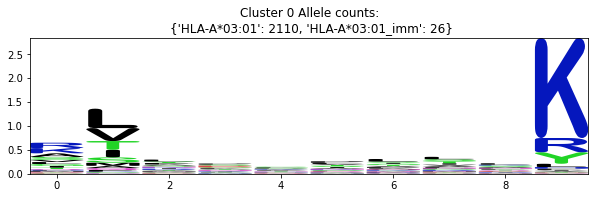

In [308]:
df = peptides_df[peptides_df['length'] == 10]
make_logo(df,length=10, cluster_num=0)

In [310]:
peptides_df[peptides_df['peptide'].str.contains("K[^K]$")]

,peptide,allele,length,leiden,louvain,immunogenic
104,RLKGPLLNKR,HLA-A*03:01,10,5,2,0
122,KTSDVVLKR,HLA-A*03:01,9,3,0,0
139,LALEGSLQKR,HLA-A*03:01,10,1,1,0
178,IQNVPLSEKI,HLA-A*03:01,10,1,1,0
269,KSMRDQRKG,HLA-A*03:01,9,0,0,0
...,...,...,...,...,...,...
6113,TVYPVAIKY,HLA-A*03:01,9,0,0,0
6309,RIFVYFITKL,HLA-A*03:01,10,1,1,0
6313,KLYKNKSKQ,HLA-A*03:01,9,4,0,0
6475,VVFGILIKR,HLA-A*03:01,9,0,0,0


### Select metric

In [118]:
metrics = [  'sokalmichener', 'sokalsneath', 'yule', 'cosine', 'euclidean', 'l1', 'l2', 'manhattan','braycurtis', 'canberra', 'chebyshev', 'correlation', 'dice', 'hamming', 'jaccard', 'kulsinski', 'mahalanobis', 'minkowski', 'rogerstanimoto', 'russellrao']

In [ ]:
fig, axes = plt.subplots(nrows=4, ncols=5, figsize=(25,25))
for coord, metric in zip(product(range(5), range(5)), metrics):
    print("metric:", metric , coord)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, metric=metric)
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"Metric {metric}")

### Select number of principal components

In [120]:
principal_components = range(5, 30, 5)

In [121]:
list(principal_components)

[5, 10, 15, 20, 25]

In [122]:
len(list(principal_components))

5

n_pcs: 5
n_pcs: 10
n_pcs: 15
n_pcs: 20
n_pcs: 25


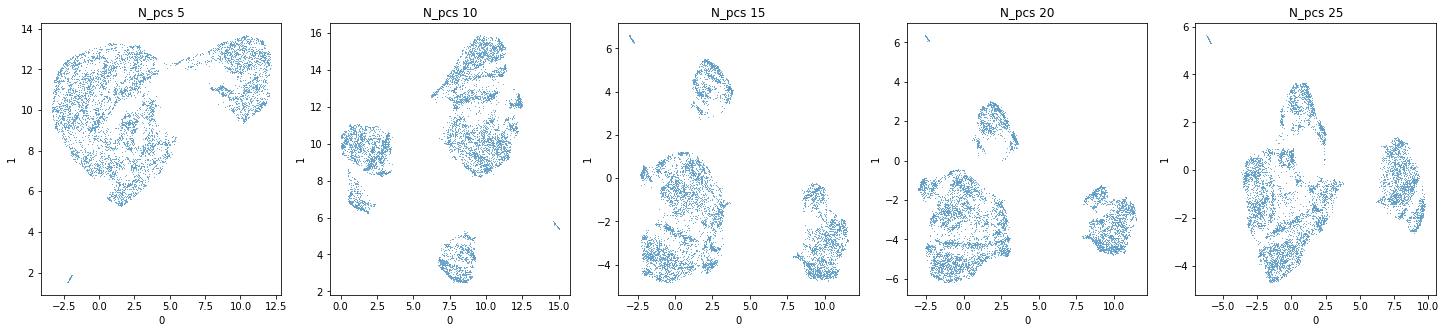

In [123]:
fig, axes = plt.subplots(ncols=5, figsize=(25,5))
for i, n_pcs in enumerate(principal_components):
    print("n_pcs:", n_pcs)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=n_pcs, metric='euclidean')
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[i]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"N_pcs {n_pcs}")

### Select number of neighbours

In [156]:
num_neighbors = range(5, 55, 5)

In [157]:
len(num_neighbors)

10

n_neighbors: 5 (0, 0)
n_neighbors: 10 (0, 1)
n_neighbors: 15 (0, 2)
n_neighbors: 20 (0, 3)
n_neighbors: 25 (0, 4)
n_neighbors: 30 (1, 0)
n_neighbors: 35 (1, 1)
n_neighbors: 40 (1, 2)
n_neighbors: 45 (1, 3)
n_neighbors: 50 (1, 4)


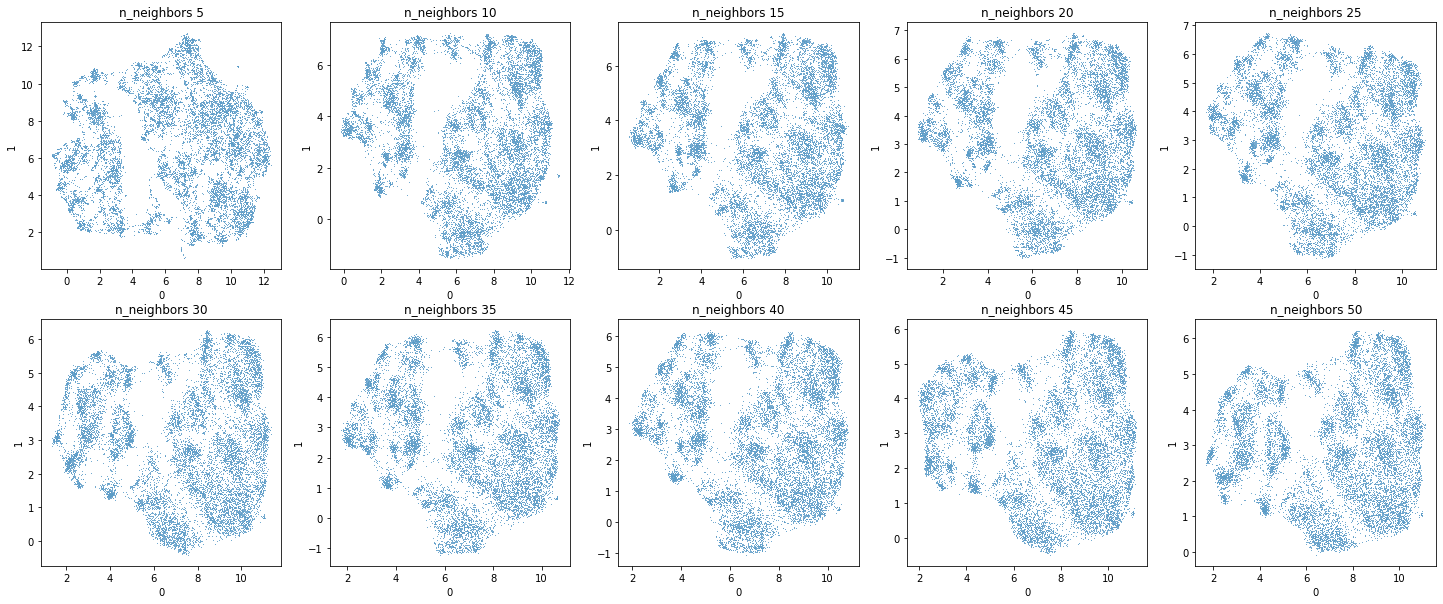

In [158]:
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(25,10))
for coord, n_neighbors in zip(product(range(2), range(5)), num_neighbors):
    print("n_neighbors:", n_neighbors , coord)
    sc.pp.neighbors(adata, n_neighbors=n_neighbors, n_pcs=20, metric='euclidean')
    sc.tl.umap(adata, min_dist=0.1)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"n_neighbors {n_neighbors}")


### Select min_dist

In [159]:
min_dists = np.linspace(0.05, 0.5, 10)

min_dist: 0.05 (0, 0)
min_dist: 0.1 (0, 1)
min_dist: 0.15000000000000002 (0, 2)
min_dist: 0.2 (0, 3)
min_dist: 0.25 (0, 4)
min_dist: 0.3 (1, 0)
min_dist: 0.35000000000000003 (1, 1)
min_dist: 0.4 (1, 2)
min_dist: 0.45 (1, 3)
min_dist: 0.5 (1, 4)


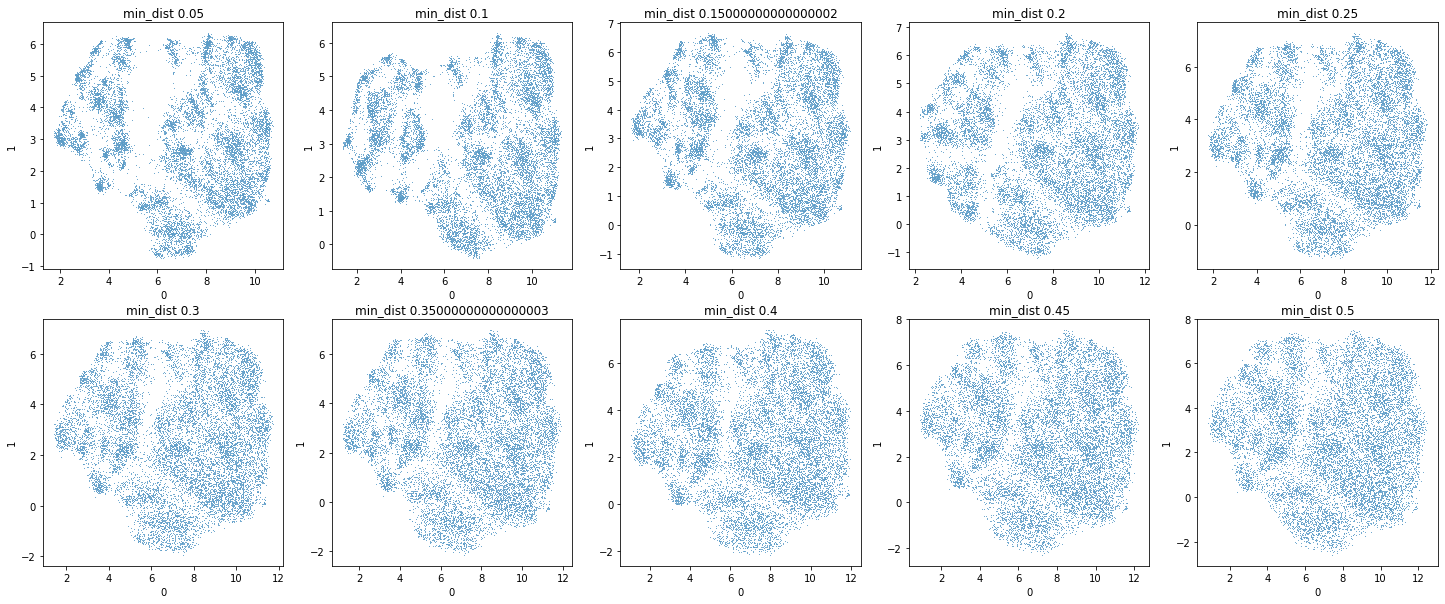

In [160]:
fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(25,10))
for coord, min_dist in zip(product(range(2), range(5)), min_dists):
    print("min_dist:", min_dist , coord)
    sc.pp.neighbors(adata, n_neighbors=30, n_pcs=20, metric='euclidean')
    sc.tl.umap(adata, min_dist=min_dist)
    df = pd.DataFrame(adata.obsm['X_umap'])
    ax = axes[coord]
    sns.scatterplot(data=df, x=0, y=1, s=1, ax=ax)
    ax.set_title(f"min_dist {min_dist}")